In [1]:
import sys 
import os

# Data analysis & stats
import pandas as pd
import numpy as np
from scipy.stats import ranksums
from scipy.sparse import csr_matrix
from scipy.stats import ttest_ind


from sklearn.preprocessing import MinMaxScaler, RobustScaler

from scipy import sparse

# Single-cell
import scanpy as sc
import scanpy.external as sce
import anndata
import scallop as sl

# Plotting & palettes
import matplotlib.pyplot as plt
import seaborn as sns
from palettable.cartocolors.qualitative import Pastel_10, Safe_10, Bold_10, Vivid_10, Prism_10, Antique_5
from palettable.colorbrewer.qualitative import Set3_12

sys.path.append('../../')
from stacked_barplots import plot_stacked_bar

sys.path.append('/media/amon/2TB-HD/Olga/Aging_and_transcriptional_noise/tools')
import transcriptional_noise as tn

seed=10

In [54]:
bold_and_vivid = Bold_10.hex_colors + Vivid_10.hex_colors + Prism_10.hex_colors
safe = Safe_10.hex_colors

# Preprocessing
We will only the take the "distal" sample from each patient. We will use the 

In [2]:
adata = sc.read('../../data/raw_data/human_lung_atlas/krasnow_lab_human_lung_cell_atlas_10x-1-remixed.h5ad')

In [3]:
# Convert to sparse matrix
adata.X = sparse.csr_matrix(adata.X)

In [4]:
# Only take distal samples in order to make fair comparisons: 
adata = adata[adata.obs['sample'].isin(['distal 1a', 'distal 2', 'distal 3'])]

In [5]:
adata.obs.head()

,nGene,nUMI,orig.ident,channel,tissue,region,percent.ribo,free_annotation,patient,sample,...,assay,disease_ontology_term_id,disease,cell_type_ontology_term_id,cell_type,sex,ethnicity_ontology_term_id,ethnicity,development_stage_ontology_term_id,development_stage
index,,,,,,,,,,,,,,,,,,,,,
P2_1_AAACCTGAGAAACCAT,1347,2914,Human Lung 10x - Patient 2,P2_1,lung,normal,0.035347,Capillary Aerocyte,2,distal 2,...,10X 3' v2 sequencing,PATO:0000461,normal,,Capillary Aerocyte,male,,unknown,HsapDv:0000140,46-year-old human stage
P2_1_AAATGCCAGATGAGAG,1713,4226,Human Lung 10x - Patient 2,P2_1,lung,normal,0.061051,Capillary Aerocyte,2,distal 2,...,10X 3' v2 sequencing,PATO:0000461,normal,,Capillary Aerocyte,male,,unknown,HsapDv:0000140,46-year-old human stage
P2_1_AACACGTTCGATCCCT,1185,2152,Human Lung 10x - Patient 2,P2_1,lung,normal,0.048327,Capillary Aerocyte,2,distal 2,...,10X 3' v2 sequencing,PATO:0000461,normal,,Capillary Aerocyte,male,,unknown,HsapDv:0000140,46-year-old human stage
P2_1_AACACGTTCGCACTCT,1378,3419,Human Lung 10x - Patient 2,P2_1,lung,normal,0.032758,Capillary Aerocyte,2,distal 2,...,10X 3' v2 sequencing,PATO:0000461,normal,,Capillary Aerocyte,male,,unknown,HsapDv:0000140,46-year-old human stage
P2_1_AACCATGCAGCTCGCA,1210,2514,Human Lung 10x - Patient 2,P2_1,lung,normal,0.050119,Capillary Aerocyte,2,distal 2,...,10X 3' v2 sequencing,PATO:0000461,normal,,Capillary Aerocyte,male,,unknown,HsapDv:0000140,46-year-old human stage


In [6]:
# Add patient age to adata.obs
age_dic = {1: 75, 2: 46, 3: 51}
adata.obs['age'] = [age_dic[pat] for pat in adata.obs['patient']]

Trying to set attribute `.obs` of view, copying.


In [7]:
adata[adata.obs['age']==75]

View of AnnData object with n_obs × n_vars = 7524 × 26450
    obs: 'nGene', 'nUMI', 'orig.ident', 'channel', 'tissue', 'region', 'percent.ribo', 'free_annotation', 'patient', 'sample', 'location', 'magnetic.selection', 'preparation.site', 'compartment', 'tissue_ontology_term_id', 'tissue_original', 'assay_ontology_term_id', 'assay', 'disease_ontology_term_id', 'disease', 'cell_type_ontology_term_id', 'cell_type', 'sex', 'ethnicity_ontology_term_id', 'ethnicity', 'development_stage_ontology_term_id', 'development_stage', 'age'
    var: 'hgnc_gene_symbol'
    uns: 'contributors', 'default_embedding', 'layer_descriptions', 'organism', 'organism_ontology_term_id', 'preprint_doi', 'project_description', 'project_links', 'project_name', 'title', 'version'
    obsm: 'X_Compartment_tSNE', 'X_tSNE'

In [67]:
adata[adata.obs['age']==46]

View of AnnData object with n_obs × n_vars = 7524 × 26450
    obs: 'nGene', 'nUMI', 'orig.ident', 'channel', 'tissue', 'region', 'percent.ribo', 'free_annotation', 'patient', 'sample', 'location', 'magnetic.selection', 'preparation.site', 'compartment', 'tissue_ontology_term_id', 'tissue_original', 'assay_ontology_term_id', 'assay', 'disease_ontology_term_id', 'disease', 'cell_type_ontology_term_id', 'cell_type', 'sex', 'ethnicity_ontology_term_id', 'ethnicity', 'development_stage_ontology_term_id', 'development_stage', 'age', 'condition', 'ct_number', 'number'
    var: 'hgnc_gene_symbol', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'contributors', 'default_embedding', 'layer_descriptions', 'organism', 'organism_ontology_term_id', 'preprint_doi', 'project_description', 'project_links', 'project_name', 'title', 'version', 'log1p', 'hvg', 'pca', 'neighbors', 'umap', 'compartment_colors', 'cell_type_colors', 'condition_colors', 'number_colors'
    obsm: 'X_Compa

In [9]:
adata[adata.obs['age']==51]

View of AnnData object with n_obs × n_vars = 16903 × 26450
    obs: 'nGene', 'nUMI', 'orig.ident', 'channel', 'tissue', 'region', 'percent.ribo', 'free_annotation', 'patient', 'sample', 'location', 'magnetic.selection', 'preparation.site', 'compartment', 'tissue_ontology_term_id', 'tissue_original', 'assay_ontology_term_id', 'assay', 'disease_ontology_term_id', 'disease', 'cell_type_ontology_term_id', 'cell_type', 'sex', 'ethnicity_ontology_term_id', 'ethnicity', 'development_stage_ontology_term_id', 'development_stage', 'age'
    var: 'hgnc_gene_symbol'
    uns: 'contributors', 'default_embedding', 'layer_descriptions', 'organism', 'organism_ontology_term_id', 'preprint_doi', 'project_description', 'project_links', 'project_name', 'title', 'version'
    obsm: 'X_Compartment_tSNE', 'X_tSNE'

In [10]:
am_total = adata[adata.obs['cell_type'] == 'alveolar macrophage']

In [11]:
am_total.write('../../data/anndatas/annotated/Travaglini_alveolar_macrophages_no_sampling.h5ad')

In [1]:
# Check number of alveolar macrophages from each patient

In [12]:
am_total[am_total.obs['age'] == 75]

View of AnnData object with n_obs × n_vars = 3167 × 26450
    obs: 'nGene', 'nUMI', 'orig.ident', 'channel', 'tissue', 'region', 'percent.ribo', 'free_annotation', 'patient', 'sample', 'location', 'magnetic.selection', 'preparation.site', 'compartment', 'tissue_ontology_term_id', 'tissue_original', 'assay_ontology_term_id', 'assay', 'disease_ontology_term_id', 'disease', 'cell_type_ontology_term_id', 'cell_type', 'sex', 'ethnicity_ontology_term_id', 'ethnicity', 'development_stage_ontology_term_id', 'development_stage', 'age'
    var: 'hgnc_gene_symbol'
    uns: 'contributors', 'default_embedding', 'layer_descriptions', 'organism', 'organism_ontology_term_id', 'preprint_doi', 'project_description', 'project_links', 'project_name', 'title', 'version'
    obsm: 'X_Compartment_tSNE', 'X_tSNE'

In [13]:
am_total[am_total.obs['age'] == 51]

View of AnnData object with n_obs × n_vars = 4469 × 26450
    obs: 'nGene', 'nUMI', 'orig.ident', 'channel', 'tissue', 'region', 'percent.ribo', 'free_annotation', 'patient', 'sample', 'location', 'magnetic.selection', 'preparation.site', 'compartment', 'tissue_ontology_term_id', 'tissue_original', 'assay_ontology_term_id', 'assay', 'disease_ontology_term_id', 'disease', 'cell_type_ontology_term_id', 'cell_type', 'sex', 'ethnicity_ontology_term_id', 'ethnicity', 'development_stage_ontology_term_id', 'development_stage', 'age'
    var: 'hgnc_gene_symbol'
    uns: 'contributors', 'default_embedding', 'layer_descriptions', 'organism', 'organism_ontology_term_id', 'preprint_doi', 'project_description', 'project_links', 'project_name', 'title', 'version'
    obsm: 'X_Compartment_tSNE', 'X_tSNE'

In [14]:
am_total[am_total.obs['age'] == 46]

View of AnnData object with n_obs × n_vars = 3848 × 26450
    obs: 'nGene', 'nUMI', 'orig.ident', 'channel', 'tissue', 'region', 'percent.ribo', 'free_annotation', 'patient', 'sample', 'location', 'magnetic.selection', 'preparation.site', 'compartment', 'tissue_ontology_term_id', 'tissue_original', 'assay_ontology_term_id', 'assay', 'disease_ontology_term_id', 'disease', 'cell_type_ontology_term_id', 'cell_type', 'sex', 'ethnicity_ontology_term_id', 'ethnicity', 'development_stage_ontology_term_id', 'development_stage', 'age'
    var: 'hgnc_gene_symbol'
    uns: 'contributors', 'default_embedding', 'layer_descriptions', 'organism', 'organism_ontology_term_id', 'preprint_doi', 'project_description', 'project_links', 'project_name', 'title', 'version'
    obsm: 'X_Compartment_tSNE', 'X_tSNE'

In [15]:
# Subsample the young fraction to have the same number of cells in the two age groups: 

In [16]:
n_cells_per_age = adata[adata.obs['age']==75].shape[0]
young_cells_46 = adata[adata.obs['age'] == 46].obs.sample(n_cells_per_age).index.tolist()
young_cells_51 = adata[adata.obs['age'] == 51].obs.sample(n_cells_per_age).index.tolist()

In [17]:
old_cells = adata[adata.obs['age']==75].obs_names.tolist()

In [18]:
adata = adata[young_cells_46 + young_cells_51 + old_cells,:]

In [19]:
sc.pp.normalize_total(adata, target_sum=1e4)

/home/amon/anaconda3/lib/python3.7/site-packages/scanpy/preprocessing/_normalization.py:155: UserWarning: Revieved a view of an AnnData. Making a copy.
  view_to_actual(adata)


In [20]:
sc.pp.log1p(adata)

In [21]:
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)

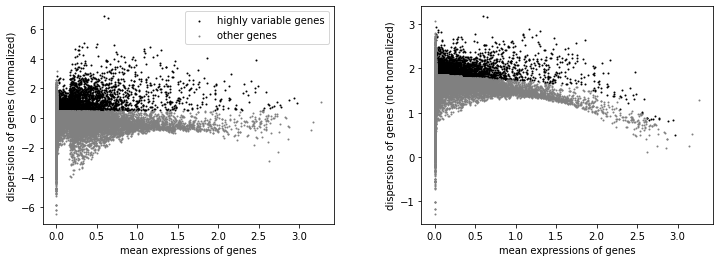

In [22]:
sc.pl.highly_variable_genes(adata)

In [23]:
sc.pp.pca(adata)

In [24]:
# Batch-effect correction using patient as the batch category
sce.pp.harmony_integrate(adata, key='patient')

2022-02-10 15:45:06,433 - harmonypy - INFO - Iteration 1 of 10

2022-02-10 15:45:06,433 - scallop / harmonypy - INFO - Iteration 1 of 10
2022-02-10 15:45:27,382 - harmonypy - INFO - Iteration 2 of 10

2022-02-10 15:45:27,382 - scallop / harmonypy - INFO - Iteration 2 of 10
2022-02-10 15:45:47,744 - harmonypy - INFO - Iteration 3 of 10

2022-02-10 15:45:47,744 - scallop / harmonypy - INFO - Iteration 3 of 10
2022-02-10 15:46:08,561 - harmonypy - INFO - Converged after 3 iterations

2022-02-10 15:46:08,561 - scallop / harmonypy - INFO - Converged after 3 iterations


In [25]:
sc.pp.neighbors(adata, use_rep='X_pca_harmony')

In [26]:
sc.tl.umap(adata)

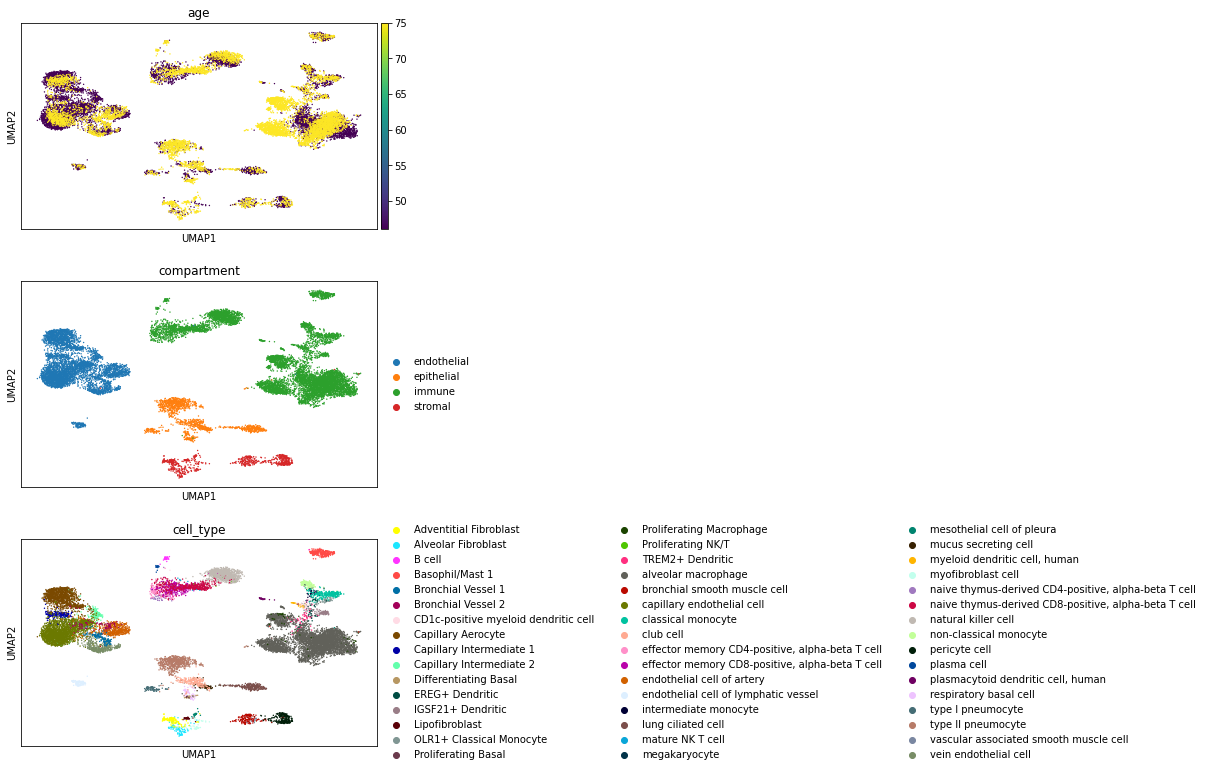

In [68]:
sc.pl.umap(adata, color=['age', 'compartment', 'cell_type'], ncols=1)

In [69]:
adata.write('../../data/anndatas/annotated/travaglini.h5ad')

# Select 46 years old and 75 years old patient for whole-tissue change in noise analysis

In [78]:
adata = adata[adata.obs['age'].isin([46, 75])]

In [79]:
adata

View of AnnData object with n_obs × n_vars = 15048 × 26450
    obs: 'nGene', 'nUMI', 'orig.ident', 'channel', 'tissue', 'region', 'percent.ribo', 'free_annotation', 'patient', 'sample', 'location', 'magnetic.selection', 'preparation.site', 'compartment', 'tissue_ontology_term_id', 'tissue_original', 'assay_ontology_term_id', 'assay', 'disease_ontology_term_id', 'disease', 'cell_type_ontology_term_id', 'cell_type', 'sex', 'ethnicity_ontology_term_id', 'ethnicity', 'development_stage_ontology_term_id', 'development_stage', 'age', 'condition', 'ct_number', 'number'
    var: 'hgnc_gene_symbol', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'contributors', 'default_embedding', 'layer_descriptions', 'organism', 'organism_ontology_term_id', 'preprint_doi', 'project_description', 'project_links', 'project_name', 'title', 'version', 'log1p', 'hvg', 'pca', 'neighbors', 'umap', 'compartment_colors', 'cell_type_colors', 'condition_colors', 'number_colors'
    obsm: 'X_Comp

In [80]:
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
sc.pp.pca(adata)
sce.pp.harmony_integrate(adata, key='patient')

Trying to set attribute `.uns` of view, copying.
2022-02-21 13:21:15,625 - harmonypy - INFO - Iteration 1 of 10

2022-02-21 13:21:15,625 - scallop / harmonypy - INFO - Iteration 1 of 10
2022-02-21 13:21:21,693 - harmonypy - INFO - Iteration 2 of 10

2022-02-21 13:21:21,693 - scallop / harmonypy - INFO - Iteration 2 of 10
2022-02-21 13:21:27,849 - harmonypy - INFO - Iteration 3 of 10

2022-02-21 13:21:27,849 - scallop / harmonypy - INFO - Iteration 3 of 10
2022-02-21 13:21:34,504 - harmonypy - INFO - Iteration 4 of 10

2022-02-21 13:21:34,504 - scallop / harmonypy - INFO - Iteration 4 of 10
2022-02-21 13:21:40,122 - harmonypy - INFO - Iteration 5 of 10

2022-02-21 13:21:40,122 - scallop / harmonypy - INFO - Iteration 5 of 10
2022-02-21 13:21:45,741 - harmonypy - INFO - Iteration 6 of 10

2022-02-21 13:21:45,741 - scallop / harmonypy - INFO - Iteration 6 of 10
2022-02-21 13:21:51,504 - harmonypy - INFO - Iteration 7 of 10

2022-02-21 13:21:51,504 - scallop / harmonypy - INFO - Iteration 

In [81]:
sc.pp.neighbors(adata, use_rep='X_pca_harmony')

In [82]:
sc.tl.umap(adata)

In [83]:
adata.obs['condition'] = adata.obs['age'].astype('category')

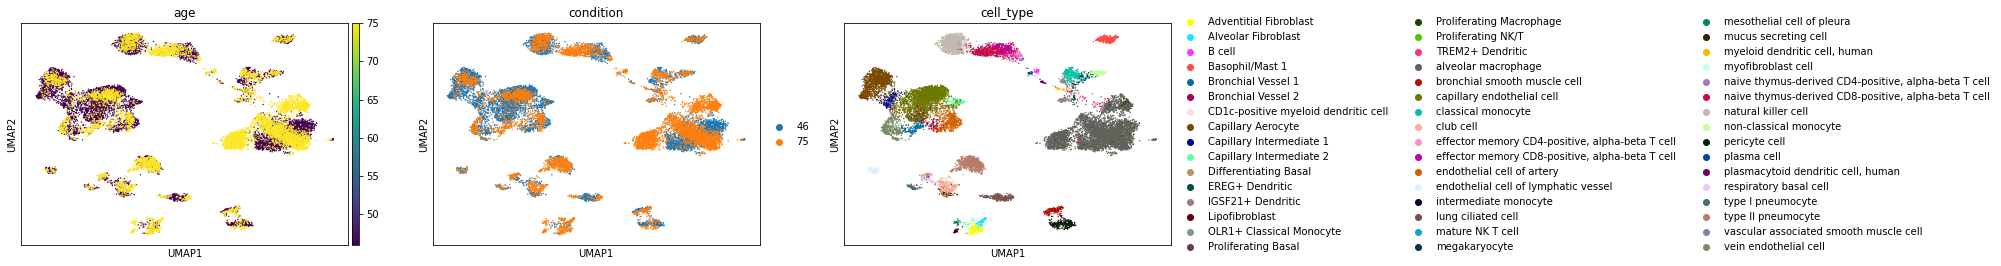

In [84]:
sc.pl.umap(adata, color=['age' , 'condition', 'cell_type'])

In [85]:
adata.write('../../data/anndatas/annotated/Travaglini_young_old.h5ad')

In [146]:
# adata.obs.loc[:, ['cell_type', 'compartment', 'ct_number']].to_csv('../../output/figs/elife/elife_fig4_supp1/HLCA_cell_type_annotations')

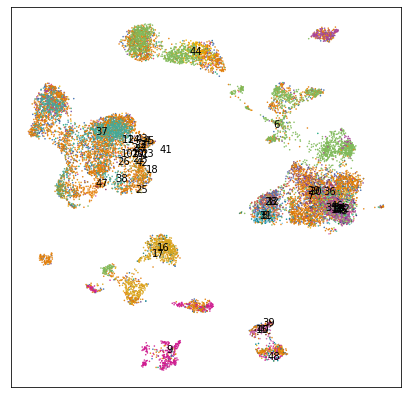

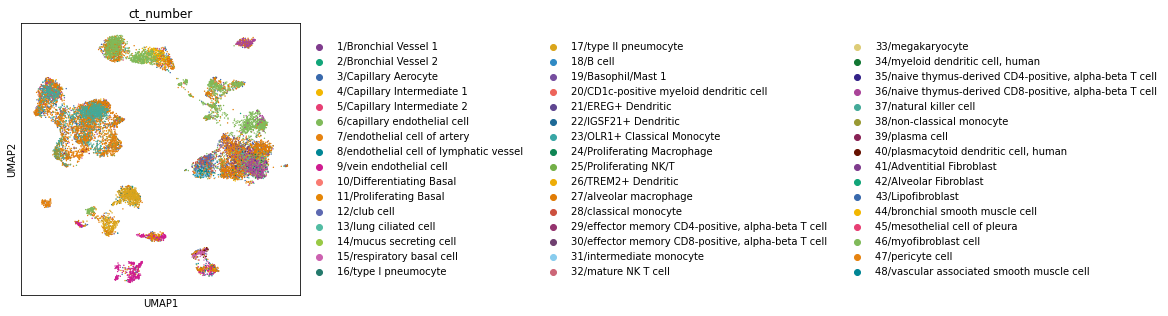

<Figure size 432x288 with 0 Axes>

In [151]:
# adata = add_numbers_to_ct(adata)
umap_ct_numbers(adata, 'HLCA')
umap_ct_legend(adata, 'HLCA')

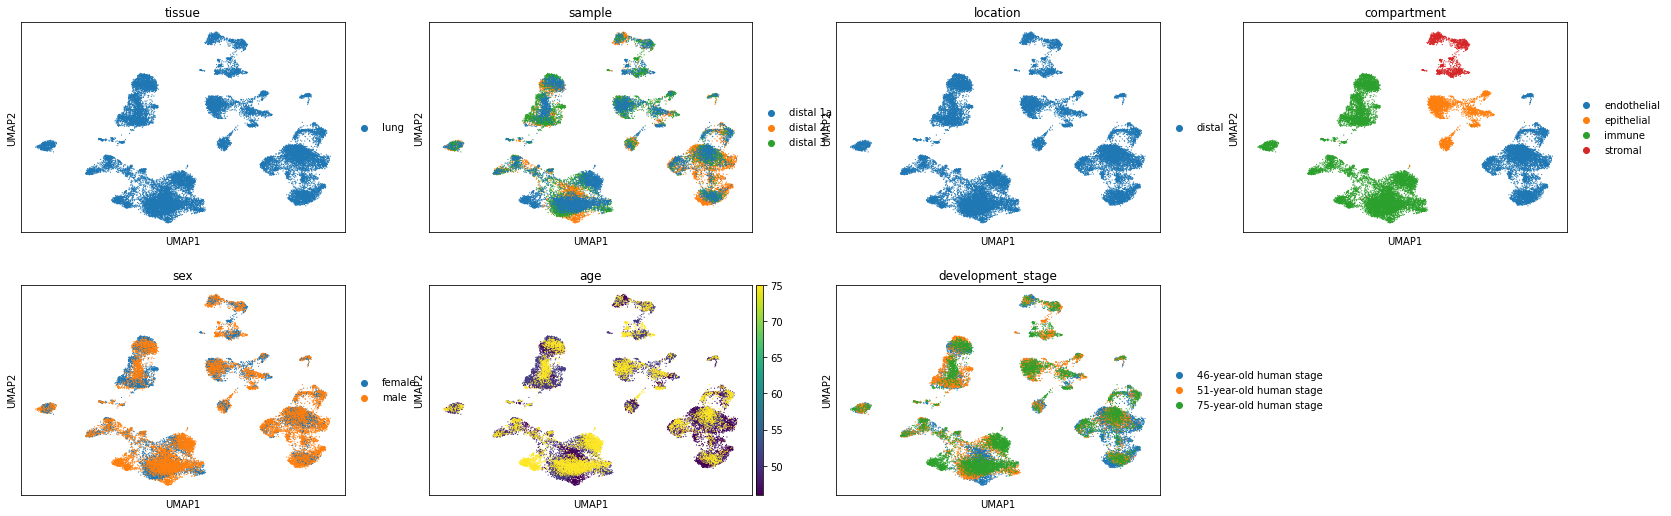

In [ ]:
sc.pl.umap(adata, color=['tissue', 'sample', 'location', 'compartment', 'sex', 'age', 'development_stage'], ncols=4)

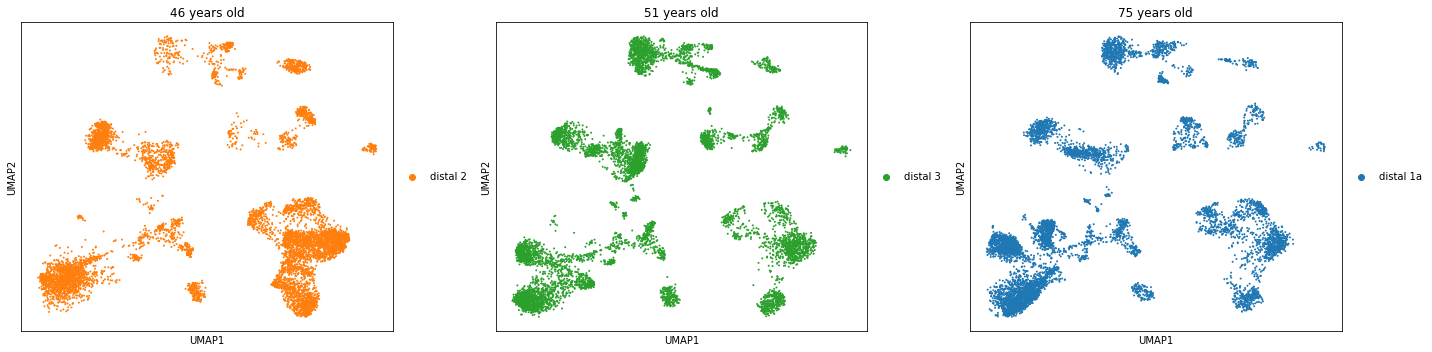

In [ ]:
fig, (ax0, ax1, ax2) = plt.subplots(1, 3, figsize=(20, 5))
sc.pl.umap(adata[adata.obs['age']==46], color='sample', ax=ax0, title='46 years old', show=False)
sc.pl.umap(adata[adata.obs['age']==51], color='sample', ax=ax1, title='51 years old', show=False)
sc.pl.umap(adata[adata.obs['age']==75], color='sample', ax=ax2, title='75 years old', show=False)
plt.tight_layout()
plt.savefig('../output/figs/hlca/samples_per_patient.svg')
plt.savefig('../output/figs/hlca/samples_per_patient.png', dpi=400)

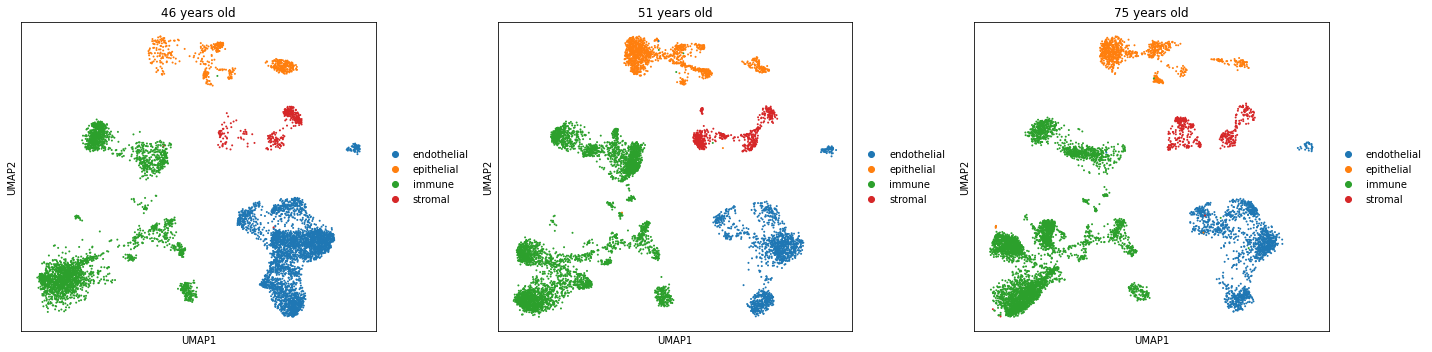

In [28]:
fig, (ax0, ax1, ax2) = plt.subplots(1, 3, figsize=(20, 5))
sc.pl.umap(adata[adata.obs['age']==46], color='compartment', ax=ax0, title='46 years old', show=False)
sc.pl.umap(adata[adata.obs['age']==51], color='compartment', ax=ax1, title='51 years old', show=False)
sc.pl.umap(adata[adata.obs['age']==75], color='compartment', ax=ax2, title='75 years old', show=False)
plt.tight_layout()
plt.savefig('../output/figs/hlca/compartment_per_patient.svg')
plt.savefig('../output/figs/hlca/compartment_per_patient.png', dpi=400)

/home/amon/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:5: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations. 
  """


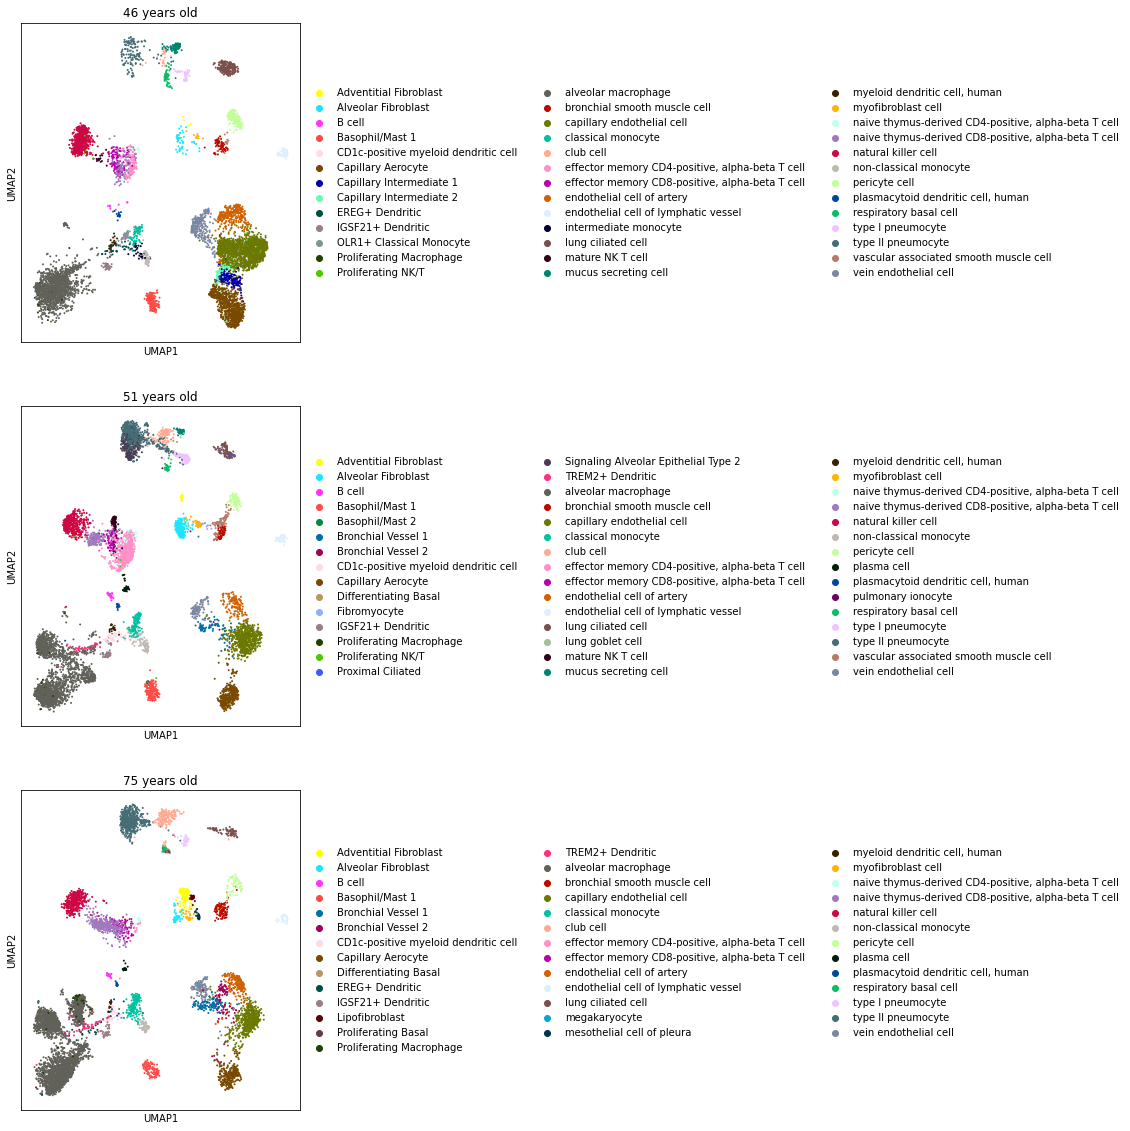

In [29]:
fig, (ax0, ax1, ax2) = plt.subplots(3, 1, figsize=(5, 20))
sc.pl.umap(adata[adata.obs['age']==46], color='cell_type', ax=ax0, title='46 years old', show=False)
sc.pl.umap(adata[adata.obs['age']==51], color='cell_type', ax=ax1, title='51 years old', show=False)
sc.pl.umap(adata[adata.obs['age']==75], color='cell_type', ax=ax2, title='75 years old', show=False)
plt.tight_layout()
plt.savefig('../output/figs/hlca/cell_type_per_patient.svg')
plt.savefig('../output/figs/hlca/cell_type_per_patient.png', dpi=400)

In [ ]:
adata = adata[adata.obs['sample'].isin(['distal 2', 'distal 1a'])]

In [ ]:
adata.obs['condition'] = ['Young' if age == 46 else 'Old' for age in adata.obs['age']]
adata.obs['donor'] = adata.obs['patient']

In [ ]:
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)

In [ ]:
sc.pp.pca(adata)

In [ ]:
sce.pp.harmony_integrate(adata, key='patient')

In [ ]:
sc.pp.neighbors(adata, use_rep='X_pca_harmony')

In [ ]:
sc.tl.umap(adata)

In [ ]:
# Repeat UMAP but with the young and the old patient
sc.pl.umap(adata, color=['patient', 'cell_type'], ncols=1)

In [ ]:
sc.pl.umap(adata, color=['tissue', 'sample', 'location', 'compartment', 'sex', 'age', 'development_stage'], ncols=4)

In [ ]:
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(15, 5))
sc.pl.umap(adata[adata.obs['age']==46], color='sample', ax=ax0, title='46 years old', show=False)
sc.pl.umap(adata[adata.obs['age']==75], color='sample', ax=ax1, title='75 years old', show=False)
plt.tight_layout()
plt.savefig('../output/figs/hlca/samples_per_patient_after_balancing.svg')
plt.savefig('../output/figs/hlca/samples_per_patient_after_balancing.png', dpi=400)

In [ ]:
adata.write('../data/anndatas/annotated/human_lung_atlas_two_patients.h5ad')

# Cell type composition
We first create a dataframe with the abundance and the percentage of each cell type in the young and the old patients.

In [ ]:
adata.obs['condition'] = ['Young' if age < 52 else 'Old' for age in adata.obs['age']]
adata.obs['donor'] = adata.obs['patient']

In [ ]:
sc.pl.umap(adata, color=['patient', 'condition'])

In [ ]:
df_ct = pd.DataFrame(index=sorted(list(set(adata.obs['cell_type'])), reverse=True), columns=list(set(adata.obs['condition'])))
for ct in set(adata.obs['cell_type']):
    for cond in set(adata.obs['condition']): 
        df_ct.loc[ct, cond] = adata[(adata.obs['cell_type'] == ct) & (adata.obs['condition'] == cond)].shape[0]    
        df_ct.loc[ct, f'{cond}_perc'] = 100*adata[(adata.obs['cell_type'] == ct) & (adata.obs['condition'] == cond)].shape[0]/adata[adata.obs['condition']==cond].shape[0]

In [ ]:
df_ct.head()

In [ ]:
df_ct.to_csv('../output/tables/ct_composition/HLCA_cell_type_composition.csv')

## Create in input for R script

In [ ]:
df_ct = pd.read_csv('../output/tables/ct_composition/HLCA_cell_type_composition.csv', index_col=0)

In [ ]:
df_comp = pd.DataFrame()
donors = set(adata.obs['donor'])
cell_types = set(adata.obs['cell_type'])

for donor in donors:
    for ct in cell_types:
        count = adata[(adata.obs['donor']==donor) & (adata.obs['cell_type']==ct)].shape[0] # same donor, same cell-type
        total = adata[adata.obs['donor']==donor].shape[0] # same donor, all cell types
        other = total - count # same donor, cell types other than ct
        
        # Fill in dataframe
        group_id = f'{ct}_{donor}'
        
        df_comp.loc[group_id, 'Cell_type'] = ct
        df_comp.loc[group_id, 'Donor'] = donor
        df_comp.loc[group_id, 'Condition'] = adata[adata.obs['donor']==donor].obs['condition'][0] #it is impossible for the same mouse to have two different ages
        
        df_comp.loc[group_id, 'Count'] = count
        df_comp.loc[group_id, 'Other'] = other
        df_comp.loc[group_id, 'Total'] = total

In [ ]:
df_comp.to_csv('../output/tables/cell_type_enrichment/input/HLCA_input_for_enrichment.csv')

In [ ]:
df_comp.head()

# Read R enrichment output file

In [ ]:
enrichment = pd.read_csv(f'../output/tables/cell_type_enrichment/output/HLCA_enrichment_output.csv')

In [ ]:
enrichment.loc[:, 'odds_ratio'] = [1/x for x in enrichment.loc[:, 'odds.ratio']] #old/young instead of young/old
enrichment = enrichment.set_index('Cell_type')

In [ ]:
enrichment.head()

In [ ]:
enrichment[enrichment['p.value'] < 0.01].loc[:, ['odds_ratio', 'p.value']].sort_values('odds_ratio', ascending=False)

In [ ]:
cell_type = 'effector memory CD4-positive, alpha-beta T cell'
adata.obs[f'{cell_type}_color'] = ['True' if cell == cell_type else 'False' for cell in adata.obs['cell_type']]
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(15, 4))
sc.pl.umap(adata[adata.obs['age']==46],color=f'{cell_type}_color', ax=ax0, title=f'{cell_type} in 46 years old donor', show=False)
sc.pl.umap(adata[adata.obs['age']==75],color=f'{cell_type}_color', ax=ax1, title=f'{cell_type} in 75 years old donor', show=False)
plt.tight_layout()
plt.savefig(f'../output/figs/hlca/{cell_type}_abundance.svg')
plt.savefig(f'../output/figs/hlca/{cell_type}_abundance.png', dpi=400)

# Compute the noise 

In [ ]:
adata

In [ ]:
sc.pl.umap(adata, color='patient')

In [ ]:
# 1) euc_dist and 4) man_dist:
adata = tn.distance_to_celltype_mean(adata, batch='patient')

In [ ]:
# 2) euc_dist_tissue_invar:
adata = tn.enge_euclidean_dist(adata)

In [ ]:
# 3) euc_dist_invar:
adata = tn.distance_to_celltype_mean_invariant(adata, batch='patient')

In [ ]:
# 5) cor_dist_median:
adata = tn.hernando_herraez(adata, batch='patient')

In [ ]:
sc.pl.umap(adata, color=['euc_dist', 'man_dist', 'euc_dist_tissue_invar', 'euc_dist_invar', 'cor_dist_median'])

In [ ]:
# adata.obs[['euc_dist', 'man_dist', 'euc_dist_tissue_invar', 'euc_dist_invar', 'cor_dist_median']].to_csv('../output/tables/human_lung_atlas/Transcriptional_noise_per_subcluster.csv')

In [ ]:
adata[adata.obs['patient'] == 1].obs.loc[:, 'age'] = 75
adata[adata.obs['patient'] == 2].obs.loc[:, 'age'] = 46

In [ ]:
# 6: Scallop
adata.obs['batch'] = adata.obs['patient']
adata.obs['condition'] = adata.obs['age']

In [ ]:
adata = tn.scallop_pipeline(adata)

In [ ]:
adata.obs.to_csv('../output/tables/human_lung_atlas/obs_data_frame.csv')

In [ ]:
# 7) GCL
gcl = tn.gcl_per_cell_type_and_batch(adata, num_divisions=30)

In [ ]:
gcl.to_csv('../output/tables/human_lung_atlas/human_lung_atlas_gcl.csv')

In [ ]:
gcl

In [ ]:
sns.boxplot(data=gcl, x='age', y='GCL')

In [ ]:
obs = pd.read_csv('../output/tables/human_lung_atlas/obs_data_frame.csv', index_col=0)

In [ ]:
gcl = pd.read_csv('../output/tables/human_lung_atlas/human_lung_atlas_gcl.csv')

In [ ]:
adata.obs = obs

In [ ]:
adata

In [ ]:
def plot_noise_vs_enrichment(df_noise, df_enrichment, method):
    fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 6))
    
    color = [ct_color[ct] for ct in df_enrichment.index]
    
    X = df_noise[method]
    xlabel = 'Age-related increase in noise'
        
    Y = np.log10(df_enrichment.odds_ratio)
    size = 200 + 1500 * ((df_enrichment.prob - np.min(df_enrichment.prob))/(np.max(df_enrichment.prob) - np.min(df_enrichment.prob)))
    ax.scatter(x=X, y=Y, color=color, s=size, alpha=0.5)

    for x, y, ct in zip(X, Y, df_enrichment.index):
#         ax.text(x=x, y=y, s=ct_numbers[ct], size=10)
        ax.text(x=x, y=y, s=ct, size=10)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Old/Young odds ratio')

    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

In [ ]:
plot_noise_vs_enrichment(diff, enrichment, method='scallop_noise')
plt.savefig('../../output/figs/human_lung_atlas/noise_vs_enrichment.svg')
plt.savefig('../../output/figs/human_lung_atlas/noise_vs_enrichment.png', dpi=400)